# C3: base model vs fine-tuned model on one screen

The same screenshot is analysed three ways so you can see **what each part changes**:

| Arm | Weights | How the screen is fed and read |
|---|---|---|
| **A** base, default path | Qwen2-VL-2B, 4-bit | shrunk to fit 720x1280, answer decoded freely (up to 256 tokens) |
| **B** base, contract path | the same base weights | resized to the adapter's pixel budget, verdict read from **one token**, decoding stops after the box |
| **C** fine-tuned | base + LoRA adapter | the contract path, as shipped in the app |

**How to read the result**
* **A to B (speed):** any difference comes from the *inference design*: fewer image pixels, one-token verdict, early stop. Nothing here is trained.
* **B to C (quality):** fine-tuning is what makes the verdict and the answer usable. It is **not** a speed claim: the adapter adds a little computation, so C is not faster than B. Compare what each arm *answers*, not only how long it takes.
* The **model load time** (cold start) is shown separately, because a first run that includes loading the model is much slower than later screens.

This notebook measures **one screen on this computer**. It shows speed and what each model says. It is **not** accuracy evidence: that is in `C3_v3_measured_results.ipynb` (AUC 0.594 to 0.814 on 425 screens).

Close the HEART app and any other notebook holding the model first (4 GB GPU). Run the cells from top to bottom; expect about 2 minutes in total.

Screen : 03_null_text.jpg  1080x1920  (2.07 megapixels)
Adapter: c3_v3_vision_1ep   alert level 0.30075
GPU    : NVIDIA GeForce RTX 3050 Laptop GPU, 3300 MiB free (needs about 2000)


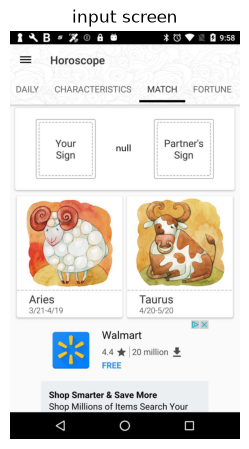

In [1]:
import sys, json, time, gc
from pathlib import Path
C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'demo_inputs').exists())
sys.path.insert(0, str(C3.parent))
import vision_oracle.services.oracle_service   # must be imported first (path guard for the local package)
import matplotlib.pyplot as plt
from PIL import Image
import torch
from local_vision_oracle.engine import TransformersInferenceBackend, load_inference_contract, contract_messages
from local_vision_oracle import model_compare as mc

# ---- Choose what to compare (edit these) --------------------------------------------------------------------
IMAGE   = C3 / 'demo_inputs' / '03_null_text.jpg'            # any screenshot; try a saved phone screen too
GOLD    = 'data_binding_null'                                 # the true defect type if you know it, else None
ADAPTER = C3 / 'models' / 'c3_v3_vision_1ep'                  # also: c3_v3_fusion_1ep, c3_qwen2vl_2b_lora_step246
BASE    = C3 / 'models' / 'Qwen2-VL-2B-Instruct'
REPEATS = 3                                                    # timed runs per arm (median is reported)
# --------------------------------------------------------------------------------------------------------------
contract = load_inference_contract(str(ADAPTER))
messages = contract_messages(contract)
image = Image.open(IMAGE).convert('RGB')
free = torch.cuda.mem_get_info()[0] / 2**20
print(f'Screen : {IMAGE.name}  {image.width}x{image.height}  ({image.width*image.height/1e6:.2f} megapixels)')
print(f'Adapter: {ADAPTER.name}   alert level {contract.get("decision_threshold")}')
print(f'GPU    : {torch.cuda.get_device_name(0)}, {free:.0f} MiB free (needs about 2000)')
assert free > 2000, 'Not enough free GPU memory: close the HEART app and other notebooks, then restart this kernel.'
plt.figure(figsize=(3, 5.3)); plt.imshow(image); plt.axis('off'); plt.title('input screen'); plt.show()

## Arms A and B: the base model (no fine-tuning)
The base model is loaded once. Arm A uses its default path, then arm B feeds the **same weights** the way the adapter is fed.

In [2]:
results, load_s = {}, {}
t = time.perf_counter()
base = TransformersInferenceBackend(model_name_or_path=str(BASE), adapter_dir=None, quantization_bit=4, device='cuda', lazy_load=False)
load_s['base'] = time.perf_counter() - t
print(f'Base model loaded in {load_s["base"]:.0f} s')

base.inference_contract = None                                     # arm A: default path
results['A  base, default path'] = mc.measure(base, image, messages, repeats=REPEATS)
print('A done')
base.inference_contract = contract                                 # arm B: same weights, contract path
results['B  base, contract path'] = mc.measure(base, image, messages, repeats=REPEATS)
print('B done')
base.unload(); del base; gc.collect(); torch.cuda.empty_cache()
print(f'GPU memory after unloading the base model: {torch.cuda.memory_allocated()/2**20:.0f} MiB')

C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/729 [00:01<17:46,  1.47s/it]

Loading weights:   0%|          | 3/729 [00:01<05:43,  2.12it/s]

Loading weights:   1%|          | 5/729 [00:01<03:13,  3.74it/s]

...

Loading weights: 100%|██████████| 729/729 [00:12<00:00, 57.28it/s]

Base model loaded in 36 s


A done


B done


GPU memory after unloading the base model: 8 MiB


## Arm C: the fine-tuned model
The base weights are unloaded first, so only one model is ever in memory.

In [3]:
t = time.perf_counter()
tuned = TransformersInferenceBackend(model_name_or_path=str(BASE), adapter_dir=str(ADAPTER), quantization_bit=4, device='cuda', lazy_load=False)
load_s['tuned'] = time.perf_counter() - t
print(f'Base + adapter loaded in {load_s["tuned"]:.0f} s')
results['C  fine-tuned'] = mc.measure(tuned, image, messages, repeats=REPEATS)
print('C done')
tuned.unload(); del tuned; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/729 [00:01<24:06,  1.99s/it]

Loading weights:   1%|          | 4/729 [00:02<05:01,  2.40it/s]

Loading weights:   2%|▏         | 15/729 [00:02<01:04, 11.09it/s]

Loading weights:   3%|▎         | 20/729 [00:02<00:48, 14.66it/s]

...

Loading weights:  98%|█████████▊| 716/729 [00:16<00:00, 68.72it/s]

Loading weights: 100%|█████████▉| 726/729 [00:16<00:00, 49.77it/s]

Loading weights: 100%|██████████| 729/729 [00:16<00:00, 43.79it/s]

Base + adapter loaded in 21 s


C done


## Results

In [4]:
def parse(out):
    try: return json.loads(out[out.index('{'): out.rindex('}') + 1])
    except Exception: return None

print(f'{"arm":<26}{"total":>10}{"verdict":>10}{"box":>9}{"image px":>11}{"img tokens":>12}{"peak VRAM":>11}')
for name, r in results.items():
    v = f'{r["verdict_ms"]:.0f} ms' if r['verdict_ms'] is not None else '-'
    b = f'{r["box_ms"]:.0f} ms' if r['box_ms'] is not None else '-'
    print(f'{name:<26}{r["total_ms"]/1000:>8.2f} s{v:>10}{b:>9}{r["image_px"]:>11,}{r["visual_tokens"]:>12,}{r["peak_vram_mib"]:>9.0f} MiB')
print(f'\nModel load (cold start): base {load_s["base"]:.0f} s, base + adapter {load_s["tuned"]:.0f} s')
print('\nWhat each model answered')
for name, r in results.items():
    obj = parse(r['output'])
    kind = (obj or {}).get('defect_type', 'unparseable answer') if obj else 'unparseable answer'
    ok = '' if GOLD is None else ('  <- correct type' if kind == GOLD else '  <- not the true type')
    print(f'  {name}: {kind}{ok}')
    print('     ' + r['output'].replace(chr(10), ' ')[:200])

arm                            total   verdict      box   image px  img tokens  peak VRAM
A  base, default path         9.35 s   9278 ms        -    921,600       1,196     1854 MiB
B  base, contract path        7.27 s    714 ms  6548 ms    261,888         336     1696 MiB
C  fine-tuned                13.98 s   1005 ms 11891 ms    261,888         336     1768 MiB

Model load (cold start): base 36 s, base + adapter 21 s

What each model answered
  A  base, default path: none  <- not the true type
     {"has_defect": false, "defect_type": "none", "bounding_box": [100, 200, 490, 380]}
  B  base, contract path: text_truncation  <- not the true type
     {"has_defect": true, "defect_type": "text_truncation", "bounding_box": [125, 200, 350, 350], "confidence": 0.3886, "defect_probability": 0.3886}
  C  fine-tuned: data_binding_null  <- correct type
     {"has_defect": true, "defect_type": "data_binding_null", "bounding_box": [278, 205, 305, 275], "confidence": 0.9992, "defect_probability": 0

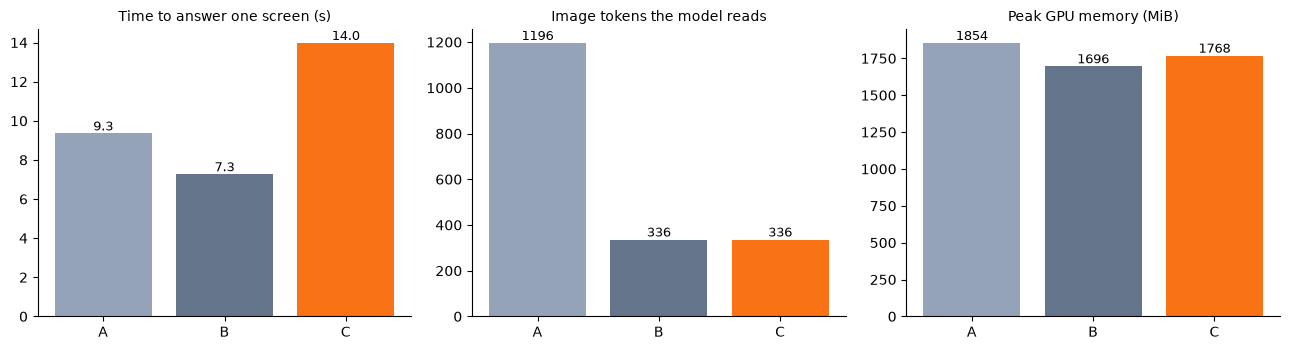

In [5]:
names = list(results)
colors = ['#94a3b8', '#64748b', '#f97316']
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, key, title, scale in ((ax[0], 'total_ms', 'Time to answer one screen (s)', 1000), (ax[1], 'visual_tokens', 'Image tokens the model reads', 1),
                             (ax[2], 'peak_vram_mib', 'Peak GPU memory (MiB)', 1)):
    vals = [results[n][key] / scale for n in names]
    bars = a.bar([n.split('  ')[0] for n in names], vals, color=colors)
    a.set_title(title, fontsize=10); a.bar_label(bars, fmt='%.1f' if key == 'total_ms' else '%.0f', fontsize=9)
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## What these numbers say

In [6]:
A, B, C = (results[n] for n in names)
print(f'* Input size: the contract path feeds {B["visual_tokens"]:,} image tokens instead of {A["visual_tokens"]:,} '
      f'({A["visual_tokens"]/B["visual_tokens"]:.1f}x fewer).')
def versus(a, b):
    r = a / b
    return f'{r:.1f}x faster' if r >= 1.05 else (f'{1/r:.1f}x slower' if r <= 0.95 else 'about the same')
print(f'* Same weights, different path: arm A {A["total_ms"]/1000:.1f} s, arm B {B["total_ms"]/1000:.1f} s (B is {versus(A["total_ms"], B["total_ms"])}). '
      'Any gap here comes from the inference design, not from training.')
print(f'* Base vs fine-tuned on the same path: B {B["total_ms"]/1000:.1f} s, C {C["total_ms"]/1000:.1f} s (C is {versus(B["total_ms"], C["total_ms"])}). '
      'Fine-tuning is not a speed gain; the adapter adds computation.')
print(f'* Fine-tuned vs the default base path: C is {versus(A["total_ms"], C["total_ms"])} per screen. '
      'Do not present the fine-tuned model as faster unless this line says so.')
print(f'* Cold start: loading the model takes about {load_s["tuned"]:.0f} s once (base {load_s["base"]:.0f} s); after that each screen takes {C["total_ms"]/1000:.1f} s.')
print('* One screen on one computer: quote it as an illustration, not as the accuracy result.')

* Input size: the contract path feeds 336 image tokens instead of 1,196 (3.6x fewer).
* Same weights, different path: arm A 9.3 s, arm B 7.3 s (B is 1.3x faster). Any gap here comes from the inference design, not from training.
* Base vs fine-tuned on the same path: B 7.3 s, C 14.0 s (C is 1.9x slower). Fine-tuning is not a speed gain; the adapter adds computation.
* Fine-tuned vs the default base path: C is 1.5x slower per screen. Do not present the fine-tuned model as faster unless this line says so.
* Cold start: loading the model takes about 21 s once (base 36 s); after that each screen takes 14.0 s.
* One screen on one computer: quote it as an illustration, not as the accuracy result.


In [7]:
out = C3 / 'results' / 'model_compare'; out.mkdir(parents=True, exist_ok=True)
stamp = time.strftime('%Y%m%d_%H%M%S')
(out / f'{stamp}_{IMAGE.stem}.json').write_text(json.dumps({'image': str(IMAGE), 'adapter': str(ADAPTER), 'gold': GOLD, 'load_s': load_s, 'arms': results}, indent=1, default=str), encoding='utf-8')
print('saved', out / f'{stamp}_{IMAGE.stem}.json')

saved D:\university\Resesarch\J26-SE-334\vision_oracle\results\model_compare\20261022_122129_03_null_text.json
